## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Andres Felipe Marin Velez" 
carnet = 1000112123


## 1) Descripción del problema 


Un sistema necesita atender tareas segun su importancia. Cada tarea tiene un código, un nombre y una prioridad numérica. El programa registra n tareas, las organiza en un Max-Heap (arreglo) para que la de mayor prioridad siempre esté en la raíz, y permite consultarla, procesarla, insertar nuevas tareas y ordenar las prioridades con HeapSort 


## 2) Requerimientos 

Lista requerimientos **funcionales** y **no funcionales**.



*Funcionales*
1. Solicitar n tareas (código, nombre, prioridad) y mostrar la lista original de prioridades en el orden ingresado.
2. Implementar MAX-HEAPIFY y BUILD-MAX-HEAP y mostrar la lista original, el Max-Heap y su representación en árbol.
3. Implementar MAXIMUM: mostrar la tarea de la raíz sin eliminarla.
4. Implementar EXTRACT-MAX: retirar la tarea de mayor prioridad, mostrarla y reorganizar el heap.
5. Permitir insertar una nueva tarea conservando la propiedad de Max-Heap.
6. Implementar HEAPSORT manual y mostrar únicamente la lista original, el Max-Heap y la lista ordenada.

*No funcionales*
1. El sistema no debe utilizar la librería heapq ni las funciones sort() y sorted() para realizar el ordenamiento mediante HeapSort.
2. MAX-HEAPIFY, EXTRACT-MAX e inserción en O(log n); BUILD-MAX-HEAP en O(n); HEAPSORT en O(n log n).
3. Validación de entradas: enteros válidos, códigos únicos y no vacíos, y manejo del heap vacío sin errores.
4. El sistema debe garantizar que la prioridad de cada padre sea mayor o igual que la de sus hijos después de cada operación que modifique el Heap.
5. Código modular, con funciones independientes y comentadas, escrito en Python 3 sin dependencias externas.

## 3) Historias de usuario 
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


1. El usuario debe registrar tareas con código, nombre y prioridad para tenerlas en el sistema.	Se muestra la lista de prioridades en el orden ingresado.
2. el usuario deb ver que las tareas se organicen en un Max-Heap para identificar rápido la más importante.	El padre es ≥ sus hijos y se muestra el árbol.
3. El usuario debe consultar la tarea más prioritaria sin retirarla para planificar mi trabajo.	Se muestra la raíz y el heap no cambia.
4. el usuario debe procesar la tarea más prioritaria para avanzar con mi lista.	Se muestra la tarea retirada y el heap queda válido.
5. El usuario debe agregar tareas nuevas en cualquier momento para reflejar imprevistos.	La nueva tarea queda en la posición correcta del heap.
6. El uaurio debe  ver las prioridades ordenadas de menor a mayor para tener una visión global.	Se muestran original, Max-Heap y lista ordenada.


## 4) Diagramas de flujo
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.


![Captura de pantalla 2026-10-27 190019.png](<attachment:Captura de pantalla 2026-10-27 190019.png>)
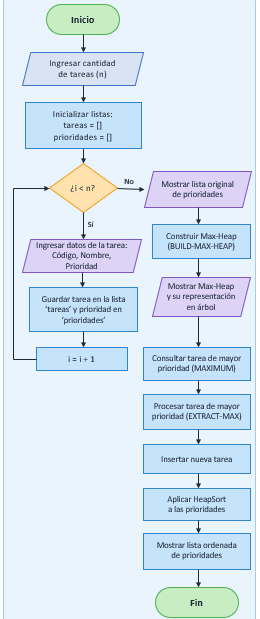

### 5) Análisis de complejidad 
El analicis de complejidad de este ejercicio es O(nlogn), ya que en el codigo cada funcion tiene su propia complejidad al ser un codigo en conjunto el O(nlogn) es la dominante, ademas de ser el mejor y el peor caso.
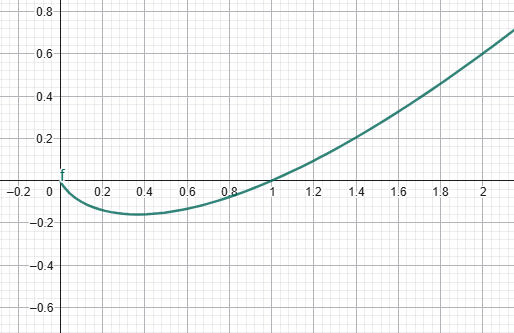

## 6) Código funcional 
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:

# Punto 1. Registrar las tareas

def registrar_tareas():
    tareas = []
    prioridades = []

    n = int(input("Ingrese la cantidad de tareas: "))

    for i in range(n):
        print("\nTarea", i + 1)

        codigo = input("Codigo: ")
        nombre = input("Nombre: ")
        prioridad = int(input("Prioridad: "))

        tarea = [codigo, nombre, prioridad]

        tareas.append(tarea)
        prioridades.append(prioridad)

    print("\nLista original de prioridades:", prioridades)

    return tareas, prioridades


# Punto 2. Construir el Max-Heap

def max_heapify(heap, i, n):
    mayor = i

    izquierda = 2 * i + 1
    derecha = 2 * i + 2

    if izquierda < n and heap[izquierda][2] > heap[mayor][2]:
        mayor = izquierda

    if derecha < n and heap[derecha][2] > heap[mayor][2]:
        mayor = derecha

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]

        max_heapify(heap, mayor, n)


def build_max_heap(heap):
    n = len(heap)

    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, i, n)


# Mostrar las prioridades del Heap

def mostrar_heap(heap):
    prioridades = []

    for tarea in heap:
        prioridades.append(tarea[2])

    print(prioridades)


# Representacion sencilla del arbol

def mostrar_arbol(heap):
    if len(heap) == 0:
        print("Heap vacio")
        return

    nivel = 0
    inicio = 0
    cantidad = 1

    while inicio < len(heap):
        fin = inicio + cantidad
        elementos = heap[inicio:fin]

        for tarea in elementos:
            print(tarea[2], end="   ")

        print()

        inicio = fin
        cantidad = cantidad * 2
        nivel = nivel + 1


# Punto 3A. Consultar la tarea de mayor prioridad

def maximum(heap):
    if len(heap) == 0:
        print("No hay tareas en el Heap")
    else:
        tarea = heap[0]

        print(
            "Tarea de mayor prioridad:",
            tarea[0], "-", tarea[1],
            "Prioridad:", tarea[2]
        )


# Punto 3B. Procesar la tarea de mayor prioridad

def extract_max(heap):
    if len(heap) == 0:
        print("No hay tareas para procesar")
        return

    tarea = heap[0]

    ultimo = heap.pop()

    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0, len(heap))

    print(
        "Tarea procesada:",
        tarea[0], "-", tarea[1],
        "Prioridad:", tarea[2]
    )

    print("Nuevo Heap:", end=" ")
    mostrar_heap(heap)


# Punto 3C. Insertar una nueva tarea

def insertar_tarea(heap):
    codigo = input("Codigo: ")
    nombre = input("Nombre: ")
    prioridad = int(input("Prioridad: "))

    tarea = [codigo, nombre, prioridad]

    heap.append(tarea)

    i = len(heap) - 1

    while i > 0:
        padre = (i - 1) // 2

        if heap[padre][2] < heap[i][2]:
            heap[padre], heap[i] = heap[i], heap[padre]
            i = padre
        else:
            break

    print("Tarea insertada correctamente")
    print("Nuevo Heap:", end=" ")
    mostrar_heap(heap)


# Punto 4. Implementar HeapSort manualmente

def heapsort(lista):
    n = len(lista)

    # Construir el Max-Heap
    for i in range(n // 2 - 1, -1, -1):
        max_heapify_lista(lista, i, n)

    # Ordenar de mayor a menor dentro del Heap
    for i in range(n - 1, 0, -1):
        lista[0], lista[i] = lista[i], lista[0]

        max_heapify_lista(lista, 0, i)


def max_heapify_lista(lista, i, n):
    mayor = i

    izquierda = 2 * i + 1
    derecha = 2 * i + 2

    if izquierda < n and lista[izquierda] > lista[mayor]:
        mayor = izquierda

    if derecha < n and lista[derecha] > lista[mayor]:
        mayor = derecha

    if mayor != i:
        lista[i], lista[mayor] = lista[mayor], lista[i]

        max_heapify_lista(lista, mayor, n)


# Programa principal

def main():
    # Punto 1
    tareas, prioridades_originales = registrar_tareas()

    # Punto 2
    print("\n--- CONSTRUCCION DEL MAX-HEAP ---")

    build_max_heap(tareas)

    print("Lista original:", prioridades_originales)

    print("Max-Heap:", end=" ")
    mostrar_heap(tareas)

    print("\nRepresentacion del arbol:")
    mostrar_arbol(tareas)

    # Punto 3A
    print("\n--- CONSULTAR MAYOR PRIORIDAD ---")
    maximum(tareas)

    # Punto 3B
    print("\n--- PROCESAR TAREA ---")
    extract_max(tareas)

    # Punto 3C
    print("\n--- INSERTAR NUEVA TAREA ---")
    insertar_tarea(tareas)

    # Punto 4
    print("\n--- HEAPSORT ---")

    prioridades_heap = []

    for tarea in tareas:
        prioridades_heap.append(tarea[2])

    print("Lista original:", prioridades_heap)

    prioridades_para_heap = prioridades_heap.copy()

    heapsort(prioridades_para_heap)

    print("Max-Heap:", end=" ")
    heap_temporal = prioridades_heap.copy()
    build_max_heap_lista(heap_temporal)
    print(heap_temporal)

    print("Lista ordenada:", prioridades_para_heap)


def build_max_heap_lista(lista):
    n = len(lista)

    for i in range(n // 2 - 1, -1, -1):
        max_heapify_lista(lista, i, n)


main()


Tarea 1

Tarea 2

Lista original de prioridades: [4, 4]

--- CONSTRUCCION DEL MAX-HEAP ---
Lista original: [4, 4]
Max-Heap: [4, 4]

Representacion del arbol:
4   
4   

--- CONSULTAR MAYOR PRIORIDAD ---
Tarea de mayor prioridad:  - 3 Prioridad: 4

--- PROCESAR TAREA ---
Tarea procesada:  - 3 Prioridad: 4
Nuevo Heap: [4]

--- INSERTAR NUEVA TAREA ---
Tarea insertada correctamente
Nuevo Heap: [4, 2]

--- HEAPSORT ---
Lista original: [4, 2]
Max-Heap: [4, 2]
Lista ordenada: [2, 4]


## 7) Tests aplicados **[15 pts]**

In [3]:

# TEST 1: MAX-HEAPIFY

def test_max_heapify():
    heap = [4, 10, 8, 3, 7]

    max_heapify_lista(heap, 0, len(heap))

    assert heap == [10, 7, 8, 3, 4]

    print("Test 1 aprobado: MAX-HEAPIFY")


# TEST 2: BUILD-MAX-HEAP

def test_build_max_heap():
    heap = [8, 4, 10, 3, 7]

    build_max_heap_lista(heap)

    assert heap == [10, 7, 8, 3, 4]

    print("Test 2 aprobado: BUILD-MAX-HEAP")


# TEST 3: MAXIMUM

def test_maximum():
    heap = [
        ["T03", "Renderizar video", 10],
        ["T05", "Actualizar aplicacion", 7],
        ["T01", "Disenar pagina web", 8],
        ["T04", "Crear base de datos", 3],
        ["T02", "Corregir errores", 4]
    ]

    cantidad = len(heap)

    maximum(heap)

    assert heap[0][2] == 10
    assert len(heap) == cantidad

    print("Test 3 aprobado: MAXIMUM")


# TEST 4: EXTRACT-MAX

def test_extract_max():
    heap = [
        ["T03", "Renderizar video", 10],
        ["T05", "Actualizar aplicacion", 7],
        ["T01", "Disenar pagina web", 8],
        ["T04", "Crear base de datos", 3],
        ["T02", "Corregir errores", 4]
    ]

    tarea = heap[0]

    ultimo = heap.pop()

    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0, len(heap))

    assert tarea[2] == 10
    assert len(heap) == 4
    assert heap[0][2] == 8

    print("Test 4 aprobado: EXTRACT-MAX")


# TEST 5: INSERTAR UNA TAREA

def test_insertar_tarea():
    heap = [
        ["T03", "Renderizar video", 10],
        ["T05", "Actualizar aplicacion", 7],
        ["T01", "Disenar pagina web", 8],
        ["T04", "Crear base de datos", 3],
        ["T02", "Corregir errores", 4]
    ]

    tarea = ["T06", "Actualizar servidor", 12]

    heap.append(tarea)

    i = len(heap) - 1

    while i > 0:
        padre = (i - 1) // 2

        if heap[padre][2] < heap[i][2]:
            heap[padre], heap[i] = heap[i], heap[padre]
            i = padre
        else:
            break

    assert heap[0][2] == 12
    assert len(heap) == 6

    print("Test 5 aprobado: INSERTAR TAREA")


# TEST 6: HEAPSORT

def test_heapsort():
    lista = [8, 4, 10, 3, 7]

    heapsort(lista)

    assert lista == [3, 4, 7, 8, 10]

    print("Test 6 aprobado: HEAPSORT")


# EJECUTAR TODOS LOS TESTS

def ejecutar_tests():
    test_max_heapify()
    test_build_max_heap()
    test_maximum()
    test_extract_max()
    test_insertar_tarea()
    test_heapsort()

    print("\nTodos los tests fueron aprobados correctamente.")


ejecutar_tests()

Test 1 aprobado: MAX-HEAPIFY
Test 2 aprobado: BUILD-MAX-HEAP
Tarea de mayor prioridad: T03 - Renderizar video Prioridad: 10
Test 3 aprobado: MAXIMUM
Test 4 aprobado: EXTRACT-MAX
Test 5 aprobado: INSERTAR TAREA
Test 6 aprobado: HEAPSORT

Todos los tests fueron aprobados correctamente.
